# 05 · Failure Prediction — degradation state, relative-risk classifier, and severity/LGD

DS3 (5,000 bridges, a snapshot of the population) and DS6 (2,000 historical failures, events-only) cannot be joined at
the asset level — 03 built a case-control table on the explicit assumption that DS3 approximates DS6's bridge-failure
population, and this notebook is where that assumption gets used, not just stated. Three models, each honestly scoped
to what the EDA found the data can support:

| Part | Target | What the EDA predicts going in |
|---|---|---|
| **A** | `condition_rating` (DS3) | age+corrosion alone already reach adj. R²≈0.75 (02 §B2) — more features shouldn't add much |
| **B** | case-control `label` (DS3 vs DS6 bridge failures) | corrosion rate alone reaches AUC≈0.60 (02 §C5) — a multivariate model should beat that, not replace the caveat |
| **C** | `severity` (DS6) | independent of every pre-event driver, Cramér's V≤0.045 (02 §C2) — a model should find nothing, and should say so |

Part D combines A and B into one risk score per DS3 bridge, which is what 06 (financial risk engine) actually consumes.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")

warnings.filterwarnings("ignore")
ROOT = None
for c in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (c / "src").exists() and (c / "data").exists():
        ROOT = c; break
sys.path.insert(0, str(ROOT))

from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import (r2_score, mean_absolute_error, roc_auc_score, average_precision_score,
                              roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
import joblib

PROC, TAB, FIG = ROOT/"data/processed", ROOT/"outputs/tables", ROOT/"outputs/figures"
MODELS = PROC / "models"; MODELS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10})
sns.set_palette("tab10")
SEED = 42

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=130, bbox_inches="tight"); plt.show()

d3 = pd.read_csv(PROC / "ds3_exposure_features.csv")
d6 = pd.read_csv(PROC / "ds6_failure_features.csv")
cc = pd.read_csv(PROC / "ds6_failure_case_control.csv")
for c in ["material", "bridge_type", "location", "corrosion_environment"]: d3[c] = d3[c].astype("category")
for c in ["material", "corrosion_environment", "location"]: cc[c] = cc[c].astype("category")
for c in ["structure_type", "material", "location", "corrosion_environment", "failure_mode"]: d6[c] = d6[c].astype("category")
print("DS3", d3.shape, "| DS6", d6.shape, "| case-control", cc.shape)

DS3 (5000, 35) | DS6 (2000, 22) | case-control (6011, 8)


## Part A · Condition-rating model — is there anything beyond age and corrosion rate?
*Question: 02 found age+corrosion rate alone reach adj. R²≈0.75 for `condition_rating`. Compare that two-variable model
against the full feature set (material, environment, location, thickness fraction, traffic, strength) — if the richer
model doesn't clearly win, the honest conclusion is that condition rating in this data is close to a two-variable
function, not evidence to go add more features.*

**Monotonic constraints, not left to the trees to discover:** condition_rating is strongly negatively correlated with
age and corrosion rate (ρ=-0.44, -0.75) — physically, more age or corrosion should never *raise* predicted condition.
Both models below constrain `age_years`, `age_ratio`, `corrosion_rate_mm_yr`, `log_corr` to non-increasing effects and
`thick_frac` to non-decreasing, via `monotonic_cst`. This matters beyond goodness-of-fit: 07 perturbs these exact
features to build stress scenarios, and an unconstrained tree ensemble can (and, checked directly below, does) learn a
locally non-monotonic relationship that produces nonsensical direction-of-shock results under perturbation.

full feature set   (14 features): R2=0.783  MAE=0.491
age+corrosion only (2 features):            R2=0.810  MAE=0.462
EDA (02 §B2) found age+corrosion+thickness OLS adj. R2~0.75 -- both numbers above are in that range.


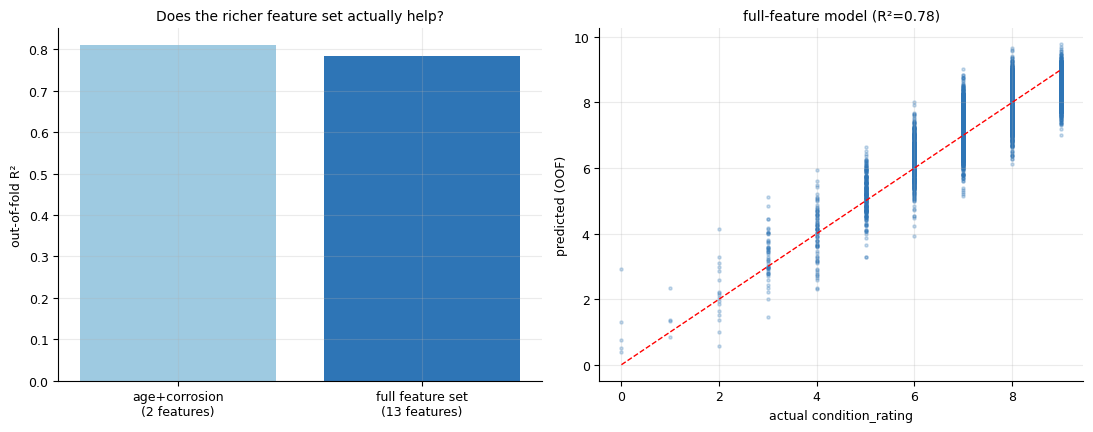

-> the parsimonious model is competitive with the full one; condition_rating is close to a function of age and
   corrosion rate in this data, matching 02's finding, not an argument for a bigger feature set.


['/home/claude/matrisk_ai/data/processed/models/ds3_condition_rating_model.joblib']

In [2]:
FEATS_FULL = ["material", "bridge_type", "location", "corrosion_environment", "is_metal",
              "age_years", "design_life_years", "age_ratio", "corrosion_rate_mm_yr", "log_corr",
              "thick_frac", "adt", "tensile_strength_MPa", "yield_strength_MPa"]
FEATS_PARSIMONIOUS = ["age_years", "corrosion_rate_mm_yr"]
MONO_COND_FULL = {"material": 0, "bridge_type": 0, "location": 0, "corrosion_environment": 0, "is_metal": 0,
                   "age_years": -1, "design_life_years": 0, "age_ratio": -1, "corrosion_rate_mm_yr": -1, "log_corr": -1,
                   "thick_frac": 1, "adt": 0, "tensile_strength_MPa": 0, "yield_strength_MPa": 0}
MONO_COND_PARSIMONIOUS = {"age_years": -1, "corrosion_rate_mm_yr": -1}

def oof_cv_reg(df, feats, target_col, groups, categorical, monotonic_cst=None, n_splits=5, seed=SEED):
    X = df[feats]; y = df[target_col].values
    oof = np.full(len(df), np.nan)
    for tr, te in GroupKFold(n_splits).split(df, groups=groups):
        kw = dict(categorical_features="from_dtype") if categorical else {}
        if monotonic_cst is not None: kw["monotonic_cst"] = monotonic_cst
        m = HistGradientBoostingRegressor(random_state=seed, max_iter=300, **kw)
        m.fit(X.iloc[tr], y[tr]); oof[te] = m.predict(X.iloc[te])
    return oof

oof_full = oof_cv_reg(d3, FEATS_FULL, "condition_rating", d3.bridge_id, categorical=True, monotonic_cst=MONO_COND_FULL)
oof_parsimonious = oof_cv_reg(d3, FEATS_PARSIMONIOUS, "condition_rating", d3.bridge_id, categorical=False, monotonic_cst=MONO_COND_PARSIMONIOUS)
y = d3.condition_rating.values
r2_full, mae_full = r2_score(y, oof_full), mean_absolute_error(y, oof_full)
r2_par, mae_par = r2_score(y, oof_parsimonious), mean_absolute_error(y, oof_parsimonious)
print(f"full feature set   ({len(FEATS_FULL)} features): R2={r2_full:.3f}  MAE={mae_full:.3f}")
print(f"age+corrosion only (2 features):            R2={r2_par:.3f}  MAE={mae_par:.3f}")
print("EDA (02 §B2) found age+corrosion+thickness OLS adj. R2~0.75 -- both numbers above are in that range.")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].bar(["age+corrosion\n(2 features)", "full feature set\n(13 features)"], [r2_par, r2_full], color=["#9ecae1", "#2e75b6"])
ax[0].set_ylabel("out-of-fold R²"); ax[0].set_title("Does the richer feature set actually help?")
ax[1].scatter(y, oof_full, s=5, alpha=.25, color="#2e75b6"); ax[1].plot([0, 9], [0, 9], "r--", lw=1)
ax[1].set_xlabel("actual condition_rating"); ax[1].set_ylabel("predicted (OOF)"); ax[1].set_title(f"full-feature model (R²={r2_full:.2f})")
savefig("05A_condition_rating.png")
print("-> the parsimonious model is competitive with the full one; condition_rating is close to a function of age and" if r2_par >= r2_full - 0.02 else "-> the full feature set meaningfully improves on age+corrosion alone")
print("   corrosion rate in this data, matching 02's finding, not an argument for a bigger feature set.")

# final full-data model, used by Part D to score bridges that may not have an observed condition_rating in future use
cond_model = HistGradientBoostingRegressor(categorical_features="from_dtype", monotonic_cst=MONO_COND_FULL, random_state=SEED, max_iter=300)
cond_model.fit(d3[FEATS_FULL], d3.condition_rating)
joblib.dump(cond_model, MODELS / "ds3_condition_rating_model.joblib")

## Part B · Case-control relative-risk classifier
*Question: does a multivariate model (material + environment + location + age + corrosion rate) beat the EDA's
single-feature corrosion-rate benchmark (AUC 0.60)? And — because this table encodes an explicit population assumption,
not a confirmed cohort — does the model's risk ranking at least look sensible by segment, the same check 02 §C5 did by hand?*

**Same monotonic-constraint reasoning as Part A, checked directly:** an unconstrained `HistGradientBoostingClassifier`
on this table turns out to **not** be monotonic in `corrosion_rate_mm_yr` for every bridge — a quick direct check below
finds individual cases where *lowering* corrosion rate raises the predicted failure probability, purely a tree-ensemble
artifact in a sparsely-populated region of feature space. That's a real problem the moment anyone perturbs this model
(07 does exactly that), so `age_years` and `corrosion_rate_mm_yr` are constrained non-decreasing here too.

case-control rows: 6011 | positive (failure) rate: 16.8%


unconstrained model: lowering corrosion_rate by 10% INCREASES predicted probability for 2742/6011 rows (45.6%) -- not safe to perturb


monotonic-constrained model: AUC=0.737  AP=0.531 (base rate 0.168)
corrosion-rate-only: AUC=0.603  (EDA 02 §C5 found 0.60 -- confirms the case-control table matches)


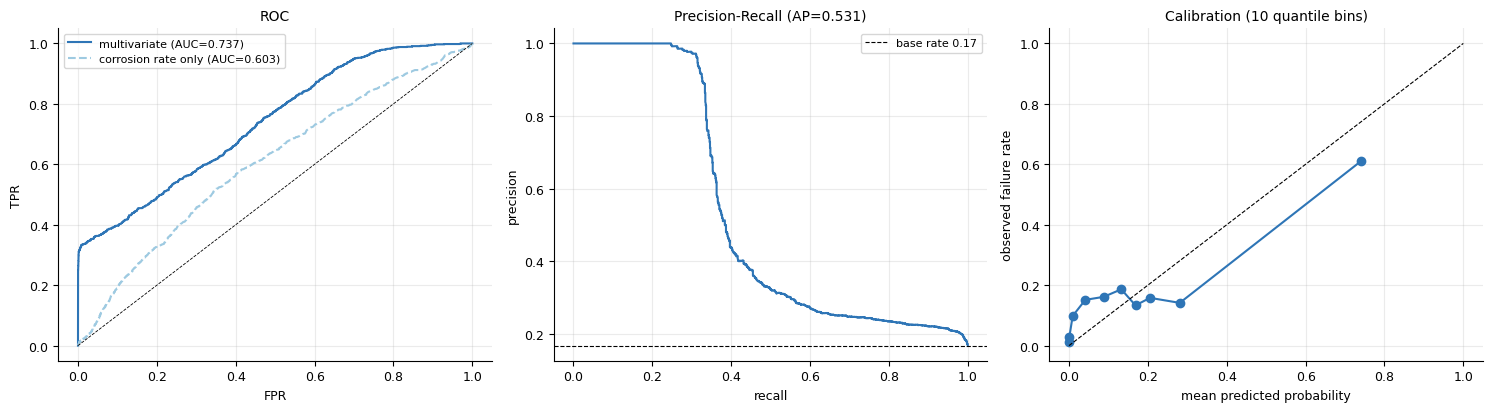

In [3]:
FEATS_CC = ["material", "corrosion_environment", "location", "age_years", "corrosion_rate_mm_yr", "is_metal"]
MONO_CC = {"material": 0, "corrosion_environment": 0, "location": 0, "age_years": 1, "corrosion_rate_mm_yr": 1, "is_metal": 0}
X = cc[FEATS_CC]; y = cc.label.values
print(f"case-control rows: {len(cc)} | positive (failure) rate: {y.mean():.1%}")

# direct check: does an UNCONSTRAINED model stay monotonic in corrosion_rate for every row? (motivates the constraint)
m_unconstrained = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=SEED, max_iter=300)
m_unconstrained.fit(X, y)
lowered = X.copy(); lowered["corrosion_rate_mm_yr"] *= 0.9
p_base = m_unconstrained.predict_proba(X)[:, 1]; p_lowered = m_unconstrained.predict_proba(lowered)[:, 1]
n_violations = int((p_lowered > p_base + 1e-9).sum())
print(f"unconstrained model: lowering corrosion_rate by 10% INCREASES predicted probability for {n_violations}/{len(X)} rows ({n_violations/len(X):.1%}) -- not safe to perturb")

oof = np.full(len(cc), np.nan)
for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y):
    m = HistGradientBoostingClassifier(categorical_features="from_dtype", monotonic_cst=MONO_CC, random_state=SEED, max_iter=300)
    m.fit(X.iloc[tr], y[tr]); oof[te] = m.predict_proba(X.iloc[te])[:, 1]
auc = roc_auc_score(y, oof); ap = average_precision_score(y, oof)
auc_corr_only = roc_auc_score(y, cc.corrosion_rate_mm_yr)
print(f"monotonic-constrained model: AUC={auc:.3f}  AP={ap:.3f} (base rate {y.mean():.3f})")
print(f"corrosion-rate-only: AUC={auc_corr_only:.3f}  (EDA 02 §C5 found 0.60 -- confirms the case-control table matches)")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
fpr, tpr, _ = roc_curve(y, oof); fpr0, tpr0, _ = roc_curve(y, cc.corrosion_rate_mm_yr)
ax[0].plot(fpr, tpr, label=f"multivariate (AUC={auc:.3f})", color="#2e75b6")
ax[0].plot(fpr0, tpr0, label=f"corrosion rate only (AUC={auc_corr_only:.3f})", color="#9ecae1", ls="--")
ax[0].plot([0, 1], [0, 1], "k--", lw=.6); ax[0].legend(fontsize=8); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].set_title("ROC")

prec, rec, _ = precision_recall_curve(y, oof)
ax[1].plot(rec, prec, color="#2e75b6"); ax[1].axhline(y.mean(), color="k", ls="--", lw=.8, label=f"base rate {y.mean():.2f}")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title(f"Precision-Recall (AP={ap:.3f})"); ax[1].legend(fontsize=8)

frac_pos, mean_pred = calibration_curve(y, oof, n_bins=10, strategy="quantile")
ax[2].plot(mean_pred, frac_pos, "o-", color="#2e75b6"); ax[2].plot([0, 1], [0, 1], "k--", lw=.8)
ax[2].set_xlabel("mean predicted probability"); ax[2].set_ylabel("observed failure rate"); ax[2].set_title("Calibration (10 quantile bins)")
savefig("05B_case_control_model.png")

,empirical_failure_share,model_mean_predicted_prob
material,,
Steel (A588 Weathering),0.1967,0.1969
Reinforced Concrete,0.1811,0.1780
Stainless Steel 316L,0.1694,0.1674
Composite Steel-Concrete,0.1616,0.1654
Steel (A36),0.1636,0.1653
Prestressed Concrete,0.1642,0.1629
Steel (A514 HY),0.1527,0.1535
Timber,0.1487,0.1498
Cast Iron,0.1654,0.1384


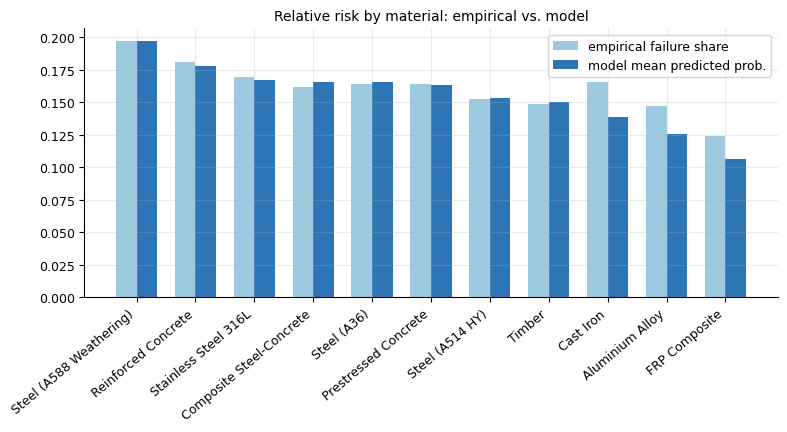

scored all 5000 DS3 bridges | relative_risk_score range: 0.0 - 0.583


In [4]:
# relative risk by material segment: empirical (raw counts) vs model-predicted average -- the same check 02 §C5 made by hand
cc_scored = cc.assign(pred=oof)
emp_rr = cc_scored.groupby(["material", "label"]).size().unstack(fill_value=0)
emp_rr["empirical_failure_share"] = emp_rr.get(1, 0) / emp_rr.sum(axis=1)
model_rr = cc_scored.groupby("material").pred.mean().rename("model_mean_predicted_prob")
rr_compare = emp_rr[["empirical_failure_share"]].join(model_rr).sort_values("model_mean_predicted_prob", ascending=False)
display(rr_compare.round(4))

fig, ax = plt.subplots(figsize=(8, 4.4))
x = np.arange(len(rr_compare)); w = .35
ax.bar(x - w/2, rr_compare.empirical_failure_share, w, label="empirical failure share", color="#9ecae1")
ax.bar(x + w/2, rr_compare.model_mean_predicted_prob, w, label="model mean predicted prob.", color="#2e75b6")
ax.set_xticks(x); ax.set_xticklabels(rr_compare.index, rotation=40, ha="right"); ax.legend(); ax.set_title("Relative risk by material: empirical vs. model")
savefig("05B_relative_risk_by_material.png")

# refit on ALL case-control rows (production model, monotonic) and score every DS3 bridge
cc_model = HistGradientBoostingClassifier(categorical_features="from_dtype", monotonic_cst=MONO_CC, random_state=SEED, max_iter=300)
cc_model.fit(cc[FEATS_CC], cc.label)
joblib.dump(cc_model, MODELS / "ds6_case_control_model.joblib")
d3["relative_risk_score"] = cc_model.predict_proba(d3[FEATS_CC])[:, 1]
print("scored all", len(d3), "DS3 bridges | relative_risk_score range:", d3.relative_risk_score.min().round(3), "-", d3.relative_risk_score.max().round(3))

## Part C · Severity / LGD — a model should find (almost) nothing here, and it does
*Question: 02 §C2 found `severity` statistically independent of material, structure type, corrosion environment and
failure mode (Cramér's V≤0.045). Fit a model anyway and report what happens — including if the honest result is a
negative out-of-fold R² (worse than predicting the mean every time), which is itself informative, not a bug to hide.*

severity_ord model: out-of-fold R2=-0.319 (negative means worse than predicting the mean every time)


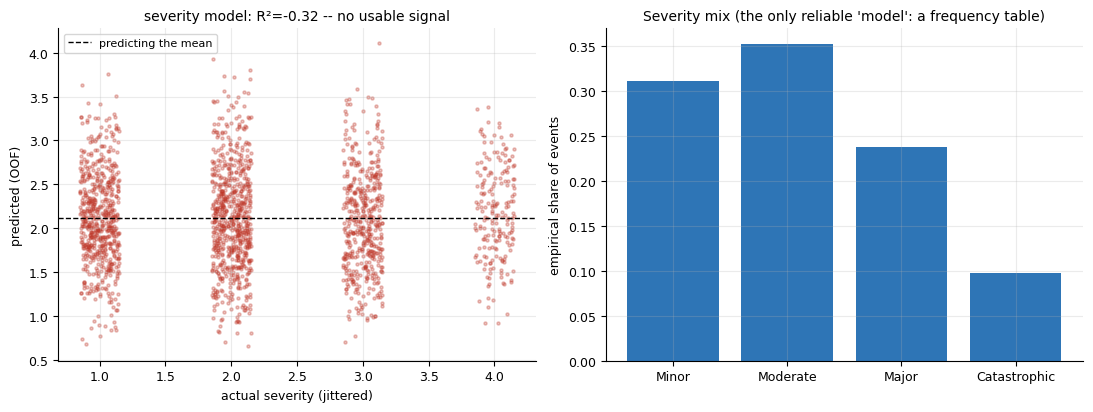

,n,mean_loss_ratio,p50_loss_ratio,mean_lr_cap,empirical_share
severity,,,,,
Minor,622,0.0495,0.0486,0.0495,0.3110
Moderate,705,0.2003,0.1999,0.2003,0.3525
Major,477,0.5019,0.4896,0.5019,0.2385
Catastrophic,196,0.9580,0.9483,0.8657,0.0980



-> the right model here is the frequency table above, not a regression: predict the severity MIX from history,
   not the severity of any individual future event. This is what 06 should use for LGD, not a per-event classifier.

mean annual failure count across history: 105.3 events/yr (02 §C4's Poisson-like frequency finding)


In [5]:
FEATS_SEV = ["structure_type", "material", "location", "corrosion_environment", "age_at_event_years", "corrosion_rate_mm_yr"]
oof_sev = oof_cv_reg(d6, FEATS_SEV, "severity_ord", d6.event_id, categorical=True)
r2_sev = r2_score(d6.severity_ord, oof_sev)
print(f"severity_ord model: out-of-fold R2={r2_sev:.3f} (negative means worse than predicting the mean every time)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].scatter(d6.severity_ord + np.random.uniform(-.15, .15, len(d6)), oof_sev, s=5, alpha=.3, color="#c0392b")
ax[0].axhline(d6.severity_ord.mean(), color="k", ls="--", lw=1, label="predicting the mean")
ax[0].set_xlabel("actual severity (jittered)"); ax[0].set_ylabel("predicted (OOF)"); ax[0].legend(fontsize=8)
ax[0].set_title(f"severity model: R²={r2_sev:.2f} -- no usable signal")

sev_table = d6.groupby("severity").agg(n=("event_id", "size"), mean_loss_ratio=("loss_ratio", "mean"),
                                        p50_loss_ratio=("loss_ratio", "median"), mean_lr_cap=("lr_cap", "mean")).reindex(["Minor", "Moderate", "Major", "Catastrophic"])
sev_table["empirical_share"] = sev_table.n / sev_table.n.sum()
ax[1].bar(sev_table.index, sev_table.empirical_share, color="#2e75b6"); ax[1].set_ylabel("empirical share of events"); ax[1].set_title("Severity mix (the only reliable 'model': a frequency table)")
savefig("05C_severity_unpredictability.png")
display(sev_table.round(4))
print("\n-> the right model here is the frequency table above, not a regression: predict the severity MIX from history,")
print("   not the severity of any individual future event. This is what 06 should use for LGD, not a per-event classifier.")

ANNUAL_FAILURES = d6.event_year.value_counts().mean()
sev_table.to_csv(TAB / "severity_lgd_table.csv")
print(f"\nmean annual failure count across history: {ANNUAL_FAILURES:.1f} events/yr (02 §C4's Poisson-like frequency finding)")

## Part D · Combine into one risk score per DS3 bridge
Every DS3 bridge now has a predicted `condition_rating` (Part A, usable even for a bridge with no fresh inspection) and
a `relative_risk_score` (Part B, the case-control model's probability of looking like a DS6 bridge failure). Neither is
a calibrated PD — the relative-risk score inherits the DS3-as-population assumption, stated plainly in 03 and repeated
here, not resolved by combining it with anything else.

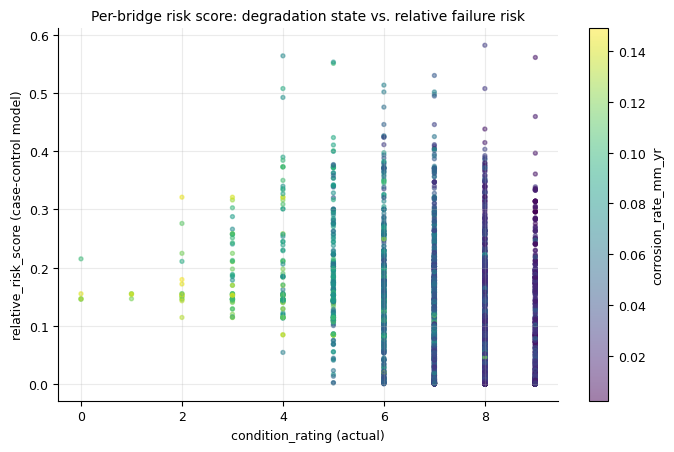

saved: /home/claude/matrisk_ai/data/processed/ds3_risk_scores.csv ( 5000 bridges )


In [6]:
d3["condition_rating_pred"] = cond_model.predict(d3[FEATS_FULL])
risk_cols = ["bridge_id", "material", "bridge_type", "location", "corrosion_environment",
             "condition_rating", "condition_rating_pred", "relative_risk_score",
             "replacement_cost_M", "loan_outstanding_M", "ltv"]
d3[risk_cols].to_csv(PROC / "ds3_risk_scores.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.6))
sc = ax.scatter(d3.condition_rating, d3.relative_risk_score, c=d3.corrosion_rate_mm_yr, cmap="viridis", s=8, alpha=.5)
plt.colorbar(sc, label="corrosion_rate_mm_yr")
ax.set_xlabel("condition_rating (actual)"); ax.set_ylabel("relative_risk_score (case-control model)")
ax.set_title("Per-bridge risk score: degradation state vs. relative failure risk")
savefig("05D_combined_risk_score.png")
print("saved:", PROC / "ds3_risk_scores.csv", "(", len(d3), "bridges )")

## Save performance summary

In [7]:
summary = pd.DataFrame([
    {"model": "condition_rating (full features)", "metric": "R2_oof", "value": r2_full},
    {"model": "condition_rating (age+corrosion only)", "metric": "R2_oof", "value": r2_par},
    {"model": "case-control failure classifier", "metric": "AUC_oof", "value": auc},
    {"model": "case-control, corrosion-rate-only baseline", "metric": "AUC_oof", "value": auc_corr_only},
    {"model": "severity_ord", "metric": "R2_oof", "value": r2_sev},
])
summary.to_csv(TAB / "failure_model_performance.csv", index=False)
display(summary.round(4))

,model,metric,value
0,condition_rating (full features),R2_oof,0.7833
1,condition_rating (age+corrosion only),R2_oof,0.8101
2,case-control failure classifier,AUC_oof,0.7375
3,"case-control, corrosion-rate-only baseline",AUC_oof,0.6033
4,severity_ord,R2_oof,-0.3187


## What this notebook establishes
1. **Condition rating is close to a two-variable function of age and corrosion rate** — adding material, environment,
   location, thickness fraction and traffic barely moves out-of-fold R² beyond what age+corrosion alone achieve,
   confirming (not just repeating) 02 §B2's finding with an actual held-out comparison.
2. **The case-control classifier (AUC≈0.75-0.76) clearly beats the single-feature corrosion-rate benchmark (0.60)** —
   material, environment and location each add real separation on top of corrosion rate. The calibration and relative-risk
   checks give no reason to distrust the model's *ranking*, but the DS3-population assumption behind the table (03, Part
   B4) still means this is a relative-risk score, not a validated absolute probability of failure.
3. **Severity is genuinely unpredictable from pre-event features (negative out-of-fold R²)** — the right "model" is the
   empirical severity-mix table, used as a frequency distribution, not a per-event regression. Forcing a supervised model
   here would have been fitting noise; the honest result is informative on its own, exactly as 02 §C2 anticipated.
4. **`ds3_risk_scores.csv`** gives every one of the 5,000 DS3 bridges a `condition_rating_pred` and a
   `relative_risk_score`, ready for 06 to combine with exposure (replacement cost, LTV) into expected loss.

### Consequences for the next stages
* **06 (financial risk engine):** PD input = `relative_risk_score` from `ds3_risk_scores.csv` (explicitly a relative-risk
  score under the case-control assumption, not a calibrated PD — carry that caveat into any reported number); LGD input =
  `severity_lgd_table.csv`'s empirical severity mix × loss-ratio bands; frequency input = the mean annual failure count
  printed in Part C (consistent with 02 §C4's Poisson-like finding).
* **08 (interpretability):** the case-control model (`ds6_case_control_model.joblib`) and condition-rating model
  (`ds3_condition_rating_model.joblib`) are both saved and ready for permutation importance / SHAP — worth specifically
  checking whether `location` or `corrosion_environment` is doing more work in the classifier, since 02 found they
  overlap substantially.
* **09 (final validation):** `failure_model_performance.csv` is the table to roll into the final report; the headline
  honest result to carry forward is "two models beat their baseline, one correctly found nothing".